# Phân loại độ chín quả chuối trên Kaggle bằng 5 mô hình

Notebook này dùng cho bài toán ba lớp:

- `under ripe / unripe` → **Xanh**
- `ripe` → **Chín**
- `past ripe / overripe` → **Quá chín**

Năm mô hình được so sánh trên **cùng một cách chia dữ liệu**:

1. MobileNetV3Small
2. EfficientNetB0
3. ResNet50
4. DenseNet121
5. InceptionV3

## Trước khi chạy

1. Mở Kaggle Notebook và chọn **Add Input** để thêm dataset.
2. Trong **Settings → Accelerator**, chọn GPU T4 hoặc P100.
3. Bật Internet nếu muốn tải trọng số ImageNet.
4. Chạy notebook từ trên xuống. Không chạy Cell train trước các Cell chuẩn bị dữ liệu.

Kết quả sẽ được lưu tại `/kaggle/working/banana_results`.

In [ ]:
print("Kaggle đã chạy")

## Cell 1 — Kiểm tra GPU và khai báo thư viện

In [1]:
!nvidia-smi

import os
import re
import gc
import json
import time
import shutil
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Tue Oct 20 03:35:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Cell 2 — Liệt kê dataset đã thêm vào Kaggle

In [2]:
INPUT_ROOT = Path("/kaggle/input")

dataset_folders = sorted([p for p in INPUT_ROOT.iterdir() if p.is_dir()])

print("Các dataset trong /kaggle/input:")
for index, folder in enumerate(dataset_folders):
    print(f"[{index}] {folder}")

if not dataset_folders:
    raise RuntimeError(
        "Không tìm thấy dataset. Hãy nhấn Add Input ở bên phải notebook rồi chạy lại cell."
    )


Các dataset trong /kaggle/input:
[0] /kaggle/input/datasets


In [3]:
!find /kaggle/input/datasets -maxdepth 5 -type d | head -100

/kaggle/input/datasets
/kaggle/input/datasets/iamchaarles
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/test
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/train


## Cell 3 — Chọn dataset

Notebook ưu tiên tự tìm dataset có từ `banana` trong tên. Nếu có nhiều dataset chuối, hãy sửa `DATASET_INDEX` theo danh sách được in ra.

In [4]:
SOURCE_DIR = Path(
    "/kaggle/input/datasets/iamchaarles/"
    "banalyzer-banana-ripeness-classification-dataset/"
    "banana_data/data"
)

TRAIN_SOURCE = SOURCE_DIR / "train"
TEST_SOURCE = SOURCE_DIR / "test"

print("Dataset:", SOURCE_DIR)
print("Dataset tồn tại:", SOURCE_DIR.exists())
print("Train tồn tại:", TRAIN_SOURCE.exists())
print("Test tồn tại:", TEST_SOURCE.exists())

Dataset: /kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data
Dataset tồn tại: True
Train tồn tại: True
Test tồn tại: True


In [5]:
!find /kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data -maxdepth 2 -type d | sort

/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/test
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/test/overripe
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/test/ripe
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/test/rotten
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/test/unripe
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/train
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/train/overripe
/kaggle/input/datasets/iamchaarles/banalyzer-banana-ripeness-classification-dataset/banana_data/data/train/ripe
/kaggl

## Cell 4 — Tự tìm thư mục chứa các lớp ảnh RGB

In [7]:
# Ba lớp dùng cho bài toán chất lượng
QUALITY_MAP = {
    "ripe": "tot",
    "overripe": "dom",
    "rotten": "thoi"
}

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Ánh xạ nhãn chất lượng:")

for old_label, new_label in QUALITY_MAP.items():
    train_count = len([
        p for p in (TRAIN_SOURCE / old_label).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ])

    test_count = len([
        p for p in (TEST_SOURCE / old_label).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ])

    print(
        f"{old_label:10s} → {new_label:4s}: "
        f"train={train_count}, test={test_count}"
    )

print("\nBỏ qua lớp: unripe")

Ánh xạ nhãn chất lượng:
ripe       → tot : train=250, test=50
overripe   → dom : train=250, test=50
rotten     → thoi: train=250, test=50

Bỏ qua lớp: unripe


## Cell 5 — Chuẩn hóa và chia dữ liệu một lần

Cell này tạo đúng một tập train, validation và test với tỷ lệ `70%–15%–15%`. Tất cả năm mô hình sẽ dùng chung các tập này.

In [8]:
# Chuẩn bị dữ liệu Tốt – Đốm – Thối
PREPARED_ROOT = Path("/kaggle/working/banana_quality_data")

TRAIN_DIR = PREPARED_ROOT / "train"
VAL_DIR = PREPARED_ROOT / "val"
TEST_DIR = PREPARED_ROOT / "test"

# Xóa dữ liệu chuẩn bị cũ nếu chạy lại Cell 5
if PREPARED_ROOT.exists():
    shutil.rmtree(PREPARED_ROOT)

for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for label in QUALITY_MAP.values():
        (split_dir / label).mkdir(parents=True, exist_ok=True)

for source_label, target_label in QUALITY_MAP.items():

    # Ảnh trong tập train gốc
    source_train_files = sorted([
        p for p in (TRAIN_SOURCE / source_label).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ])

    # Chia train gốc thành 80% train và 20% validation
    train_files, val_files = train_test_split(
        source_train_files,
        test_size=0.20,
        random_state=SEED
    )

    # Giữ nguyên tập test gốc
    test_files = sorted([
        p for p in (TEST_SOURCE / source_label).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ])

    for index, src in enumerate(train_files):
        dst = TRAIN_DIR / target_label / f"{source_label}_{index:05d}{src.suffix.lower()}"
        shutil.copy2(src, dst)

    for index, src in enumerate(val_files):
        dst = VAL_DIR / target_label / f"{source_label}_{index:05d}{src.suffix.lower()}"
        shutil.copy2(src, dst)

    for index, src in enumerate(test_files):
        dst = TEST_DIR / target_label / f"{source_label}_{index:05d}{src.suffix.lower()}"
        shutil.copy2(src, dst)

print("Đã chuẩn bị xong dữ liệu chất lượng.")

for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Test", TEST_DIR)
]:
    print(f"\n{split_name}:")
    for label in sorted(QUALITY_MAP.values()):
        count = len(list((split_dir / label).glob("*")))
        print(f"  {label}: {count} ảnh")

Đã chuẩn bị xong dữ liệu chất lượng.

Train:
  dom: 200 ảnh
  thoi: 200 ảnh
  tot: 200 ảnh

Validation:
  dom: 50 ảnh
  thoi: 50 ảnh
  tot: 50 ảnh

Test:
  dom: 50 ảnh
  thoi: 50 ảnh
  tot: 50 ảnh


## Cell 6 — Đọc dataset và kiểm tra ảnh

Found 600 files belonging to 3 classes.


I0000 00:00:1792467550.937470      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792467550.941389      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 150 files belonging to 3 classes.
Found 150 files belonging to 3 classes.
Tên các lớp: ['dom', 'thoi', 'tot']
Số lớp: 3


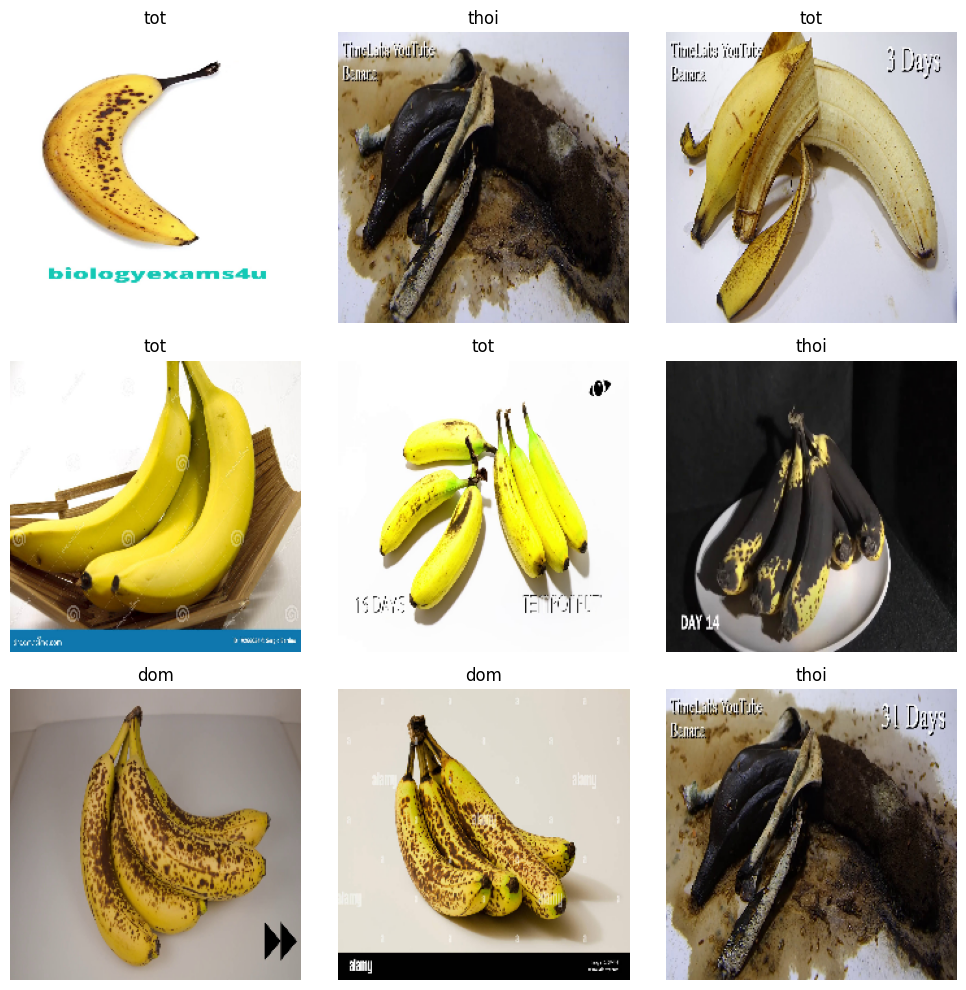

In [9]:
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Tên các lớp:", class_names)
print("Số lớp:", NUM_CLASSES)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for index in range(min(9, len(images))):
        plt.subplot(3, 3, index + 1)
        plt.imshow(images[index].numpy().astype("uint8"))
        plt.title(class_names[int(labels[index].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

## Cell 7 — Khai báo năm mô hình

Nếu Kaggle không thể tải trọng số ImageNet, hãy bật Internet trong Settings. Không nên so sánh mô hình khi một số mô hình dùng ImageNet còn số khác train từ đầu.

In [11]:
from tensorflow.keras import layers, Model

MODEL_CONFIGS = {
    "MobileNetV3Small": (
        tf.keras.applications.MobileNetV3Small,
        tf.keras.applications.mobilenet_v3.preprocess_input,
    ),
    "EfficientNetB0": (
        tf.keras.applications.EfficientNetB0,
        tf.keras.applications.efficientnet.preprocess_input,
    ),
    "ResNet50": (
        tf.keras.applications.ResNet50,
        tf.keras.applications.resnet50.preprocess_input,
    ),
    "DenseNet121": (
        tf.keras.applications.DenseNet121,
        tf.keras.applications.densenet.preprocess_input,
    ),
    "InceptionV3": (
        tf.keras.applications.InceptionV3,
        tf.keras.applications.inception_v3.preprocess_input,
    ),
}


def build_model(model_name, number_of_classes):
    constructor, preprocess_input = MODEL_CONFIGS[model_name]

    augmentation = tf.keras.Sequential(
        [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10),
            layers.RandomTranslation(0.05, 0.05),
            layers.RandomContrast(0.12),
        ],
        name="augmentation",
    )

    base_model = constructor(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3),
    )
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))
    x = augmentation(inputs)
    x = preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(number_of_classes, activation="softmax")(x)

    model = Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model, base_model

## Cell 8 — Hàm train, fine-tune và đánh giá

In [21]:
def train_and_evaluate(model_name):
    print("\n" + "=" * 72)
    print("ĐANG TRAIN:", model_name)
    print("=" * 72)

    tf.keras.backend.clear_session()
    gc.collect()

    model, base_model = build_model(model_name, len(class_names))

    stage1_weights = MODEL_DIR / f"{TASK_NAME}_{model_name}_stage1.weights.h5"
    stage2_weights = MODEL_DIR / f"{TASK_NAME}_{model_name}_stage2.weights.h5"
    final_model_path = MODEL_DIR / f"{TASK_NAME}_{model_name}.keras"

    callbacks_stage1 = [
        tf.keras.callbacks.ModelCheckpoint(
            str(stage1_weights),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1
        ),
    ]

    start_time = time.time()

    history1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        callbacks=callbacks_stage1,
        verbose=1,
    )

    model.load_weights(stage1_weights)
    stage1_val_loss = model.evaluate(val_ds, verbose=0)[0]

    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    callbacks_stage2 = [
        tf.keras.callbacks.ModelCheckpoint(
            str(stage2_weights),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1
        ),
    ]

    history2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=8,
        callbacks=callbacks_stage2,
        verbose=1,
    )

    model.load_weights(stage2_weights)
    stage2_val_loss = model.evaluate(val_ds, verbose=0)[0]

    if stage1_val_loss <= stage2_val_loss:
        model.load_weights(stage1_weights)
        selected_stage = "frozen_backbone"
    else:
        model.load_weights(stage2_weights)
        selected_stage = "fine_tuned"

    training_time = time.time() - start_time

    test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

    y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
    probabilities = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
    print(report)

    with open(
        RESULT_DIR / f"{TASK_NAME}_{model_name}_classification_report.txt",
        "w",
        encoding="utf-8",
    ) as file:
        file.write(report)

    matrix = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{TASK_NAME}_{model_name}_confusion.png", dpi=300)
    plt.show()
    plt.close()

    accuracy_values = history1.history["accuracy"] + history2.history["accuracy"]
    val_accuracy_values = history1.history["val_accuracy"] + history2.history["val_accuracy"]
    loss_values = history1.history["loss"] + history2.history["loss"]
    val_loss_values = history1.history["val_loss"] + history2.history["val_loss"]
    epochs = range(1, len(accuracy_values) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, accuracy_values, label="Train")
    plt.plot(epochs, val_accuracy_values, label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy — {model_name}")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss_values, label="Train")
    plt.plot(epochs, val_loss_values, label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Loss — {model_name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{TASK_NAME}_{model_name}_learning_curves.png", dpi=300)
    plt.show()
    plt.close()

    try:
        model.save(final_model_path)
    except Exception as error:
        print("Không lưu được model .keras, nhưng file trọng số vẫn còn:", error)

    result = {
        "Task": TASK_NAME,
        "Model": model_name,
        "Selected_Stage": selected_stage,
        "Accuracy": float(test_accuracy),
        "Macro_Precision": float(precision),
        "Macro_Recall": float(recall),
        "Macro_F1": float(f1),
        "Test_Loss": float(test_loss),
        "Training_Time_Seconds": float(training_time),
    }

    del model, base_model
    tf.keras.backend.clear_session()
    gc.collect()

    return result

In [22]:
# THƯ MỤC LƯU KẾT QUẢ PHÂN LOẠI CHẤT LƯỢNG CHUỐI

from pathlib import Path

TASK_NAME = "banana_quality"

OUTPUT_DIR = Path("/kaggle/working/banana_quality_results")
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, MODEL_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("TASK_NAME:", TASK_NAME)
print("Thư mục mô hình:", MODEL_DIR)
print("Đã chuẩn bị thư mục lưu kết quả.")

TASK_NAME: banana_quality
Thư mục mô hình: /kaggle/working/banana_quality_results/models
Đã chuẩn bị thư mục lưu kết quả.


In [23]:
from pathlib import Path

RESULT_DIR = Path("/kaggle/working/banana_quality_results/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Thư mục kết quả:", RESULT_DIR)

Thư mục kết quả: /kaggle/working/banana_quality_results/results


In [25]:
from pathlib import Path

TASK_NAME = "banana_quality"

OUTPUT_DIR = Path("/kaggle/working/banana_quality_results")
MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"

# Các tên thay thế để tránh thiếu biến
PLOT_DIR = FIGURE_DIR
TABLE_DIR = RESULT_DIR
HISTORY_DIR = RESULT_DIR

for folder in [
    OUTPUT_DIR,
    MODEL_DIR,
    RESULT_DIR,
    FIGURE_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Đã khai báo đầy đủ:")
print("MODEL_DIR  =", MODEL_DIR)
print("RESULT_DIR =", RESULT_DIR)
print("FIGURE_DIR =", FIGURE_DIR)

Đã khai báo đầy đủ:
MODEL_DIR  = /kaggle/working/banana_quality_results/models
RESULT_DIR = /kaggle/working/banana_quality_results/results
FIGURE_DIR = /kaggle/working/banana_quality_results/figures


## Cell 9 — Chạy thử một mô hình

Nên chạy Cell này trước. Nếu EfficientNetB0 chạy thành công thì mới chạy cả năm mô hình ở Cell kế tiếp.


ĐANG TRAIN: EfficientNetB0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12


E0000 00:00:1792467766.953743      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.5441 - loss: 0.9771
Epoch 1: val_loss improved from None to 0.62117, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 30s 737ms/step - accuracy: 0.6383 - loss: 0.8414 - val_accuracy: 0.7200 - val_loss: 0.6212 - learning_rate: 0.0010
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.8113 - loss: 0.5297
Epoch 2: val_loss improved from 0.62117 to 0.54549, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 665ms/step - accuracy: 0.8133 - loss: 0.5170 - val_accuracy: 0.7000 - val_loss: 0.5455 

E0000 00:00:1792467941.224888      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step - accuracy: 0.8118 - loss: 0.4509
Epoch 1: val_loss improved from None to 0.25473, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 29s 775ms/step - accuracy: 0.8550 - loss: 0.3949 - val_accuracy: 0.8933 - val_loss: 0.2547 - learning_rate: 1.0000e-05
Epoch 2/8
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 495ms/step - accuracy: 0.8315 - loss: 0.4494
Epoch 2: val_loss improved from 0.25473 to 0.23958, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 673ms/step - accuracy: 0.8600 - loss: 0.3970 - val_accuracy: 0.8800 - val_loss: 0.23

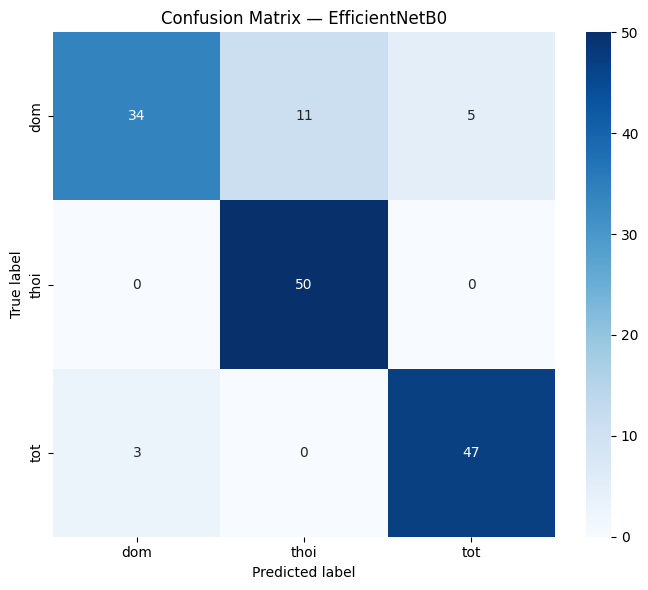

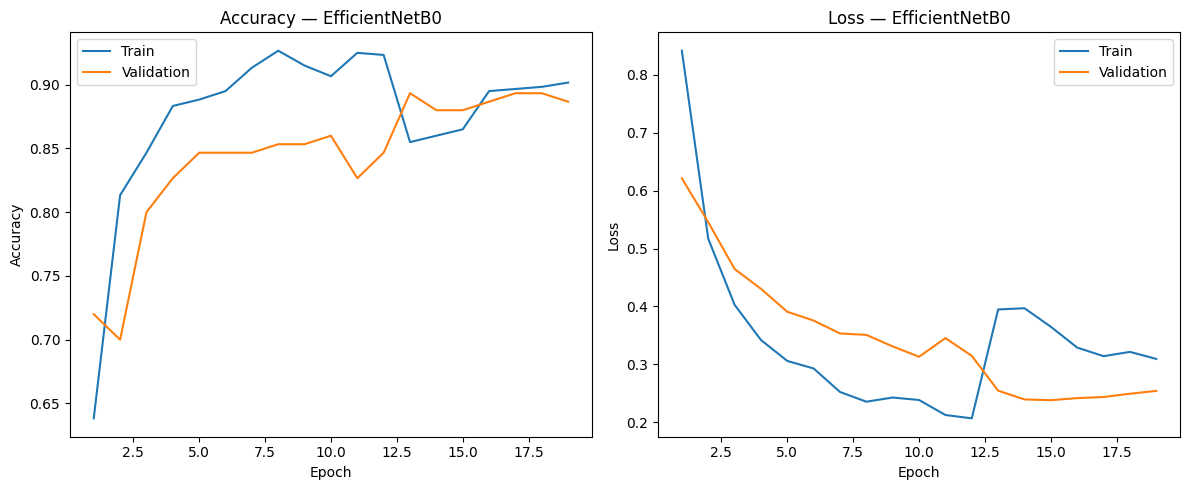

,Task,Model,Selected_Stage,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Test_Loss,Training_Time_Seconds
0,banana_quality,EfficientNetB0,fine_tuned,0.873333,0.880812,0.873333,0.868026,0.275799,277.813637


In [26]:
test_result = train_and_evaluate("EfficientNetB0")
pd.DataFrame([test_result])

## Cell 10 — Chạy đủ năm mô hình

Cell này có thể mất nhiều thời gian. Nếu đã chạy EfficientNetB0 ở Cell 9, Cell này sẽ chạy lại EfficientNetB0 để tạo một bảng kết quả thống nhất.


ĐANG TRAIN: MobileNetV3Small
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step - accuracy: 0.4422 - loss: 1.2555
Epoch 1: val_loss improved from None to 0.64568, saving model to /kaggle/working/banana_quality_results/models/banana_quality_MobileNetV3Small_stage1.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_MobileNetV3Small_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 747ms/step - accuracy: 0.5200 - loss: 1.0889 - val_accuracy: 0.7867 - val_loss: 0.6457 - learning_rate: 0.0010
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.6545 - loss: 0.7598
Epoch 2: val_loss improved from 0.64568 to 0.47258, saving model to /kaggle/working/banana_quality_results/models/banana_quality_MobileNetV3Small_stage1.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_MobileNetV3Small_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━

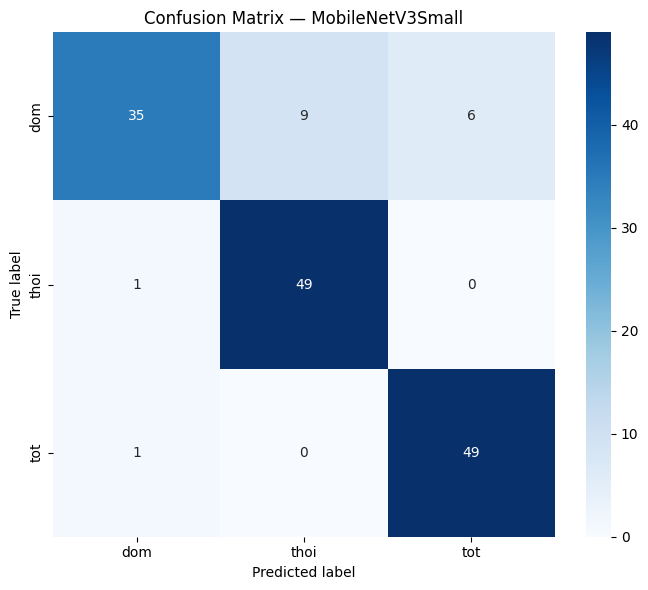

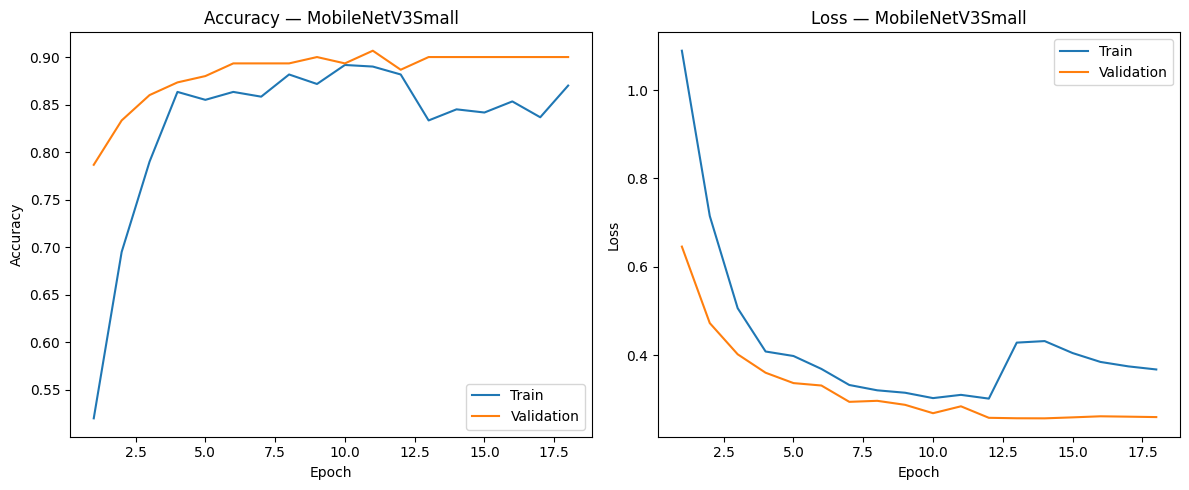


ĐANG TRAIN: EfficientNetB0
Epoch 1/12


E0000 00:00:1792468372.781299      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.4655 - loss: 1.0685
Epoch 1: val_loss improved from None to 0.65312, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 26s 820ms/step - accuracy: 0.6000 - loss: 0.9006 - val_accuracy: 0.6933 - val_loss: 0.6531 - learning_rate: 0.0010
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.7997 - loss: 0.5422
Epoch 2: val_loss improved from 0.65312 to 0.52833, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 660ms/step - accuracy: 0.8167 - loss: 0.5100 - val_accuracy: 0.7933 - val_loss: 0.5283 

E0000 00:00:1792468543.750022      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.8519 - loss: 0.3910
Epoch 1: val_loss improved from None to 0.23310, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 30s 828ms/step - accuracy: 0.8600 - loss: 0.3972 - val_accuracy: 0.9000 - val_loss: 0.2331 - learning_rate: 1.0000e-05
Epoch 2/8
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.8717 - loss: 0.3750
Epoch 2: val_loss improved from 0.23310 to 0.22055, saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_EfficientNetB0_stage2.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 676ms/step - accuracy: 0.8783 - loss: 0.3643 - val_accuracy: 0.8867 - val_loss: 0.22

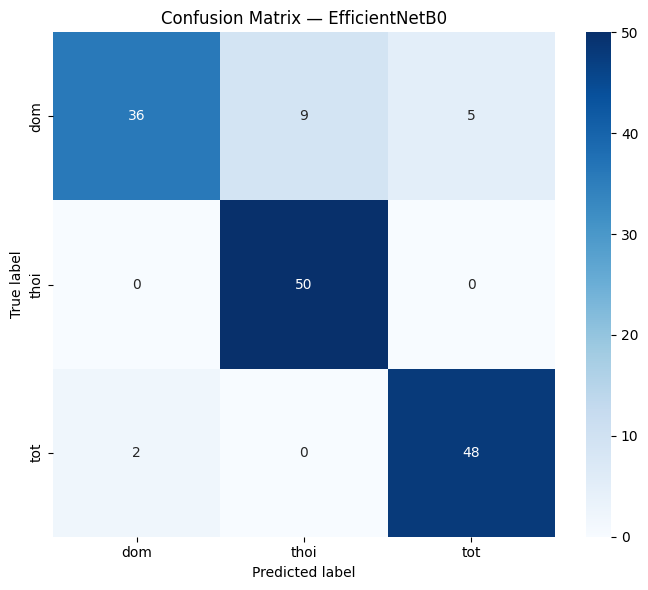

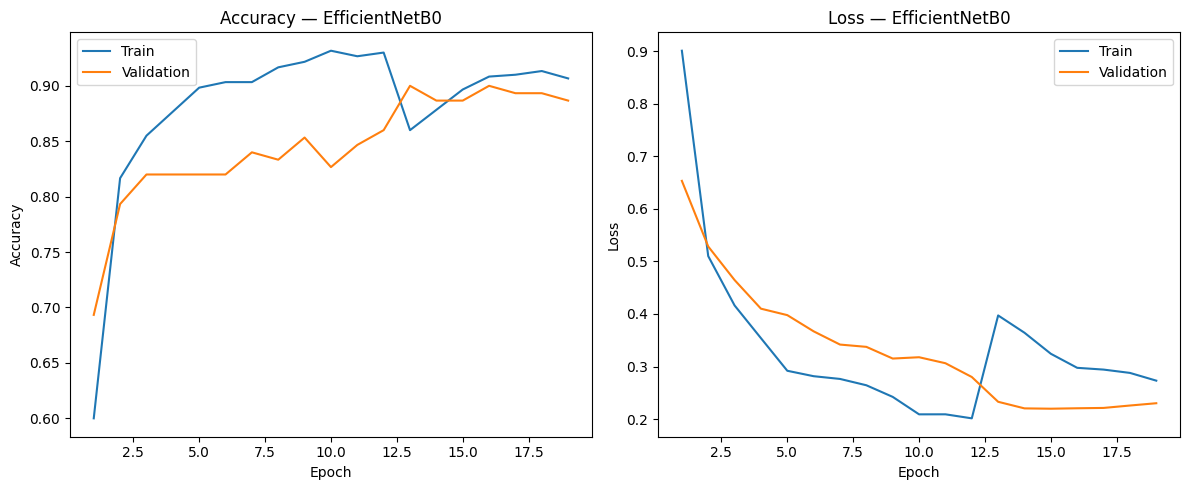


ĐANG TRAIN: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.4685 - loss: 1.2046
Epoch 1: val_loss improved from None to 0.43524, saving model to /kaggle/working/banana_quality_results/models/banana_quality_ResNet50_stage1.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_ResNet50_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 24s 834ms/step - accuracy: 0.5517 - loss: 1.0170 - val_accuracy: 0.8333 - val_loss: 0.4352 - learning_rate: 0.0010
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 491ms/step - accuracy: 0.8091 - loss: 0.4478
Epoch 2: val_loss improved from 0.43524 to 0.31880, saving model to /kaggle/working/banana_quality_results/models/banana_quality_ResNet50_stage1.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_ResNet50_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 673ms/step - accuracy: 0.83

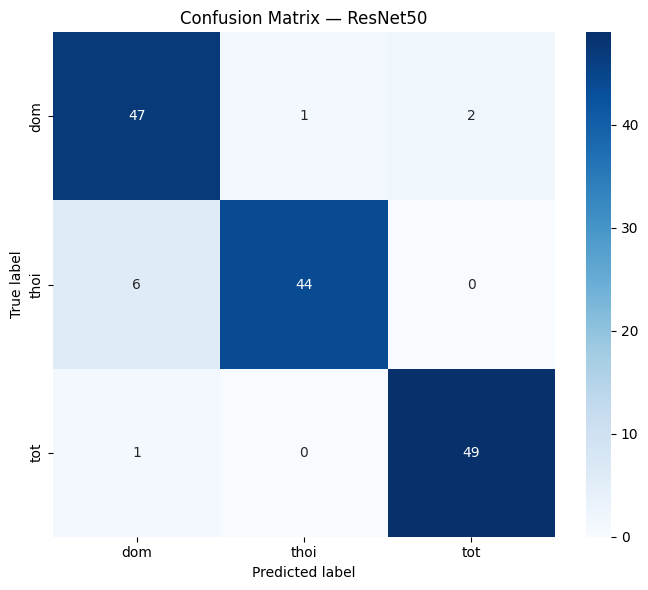

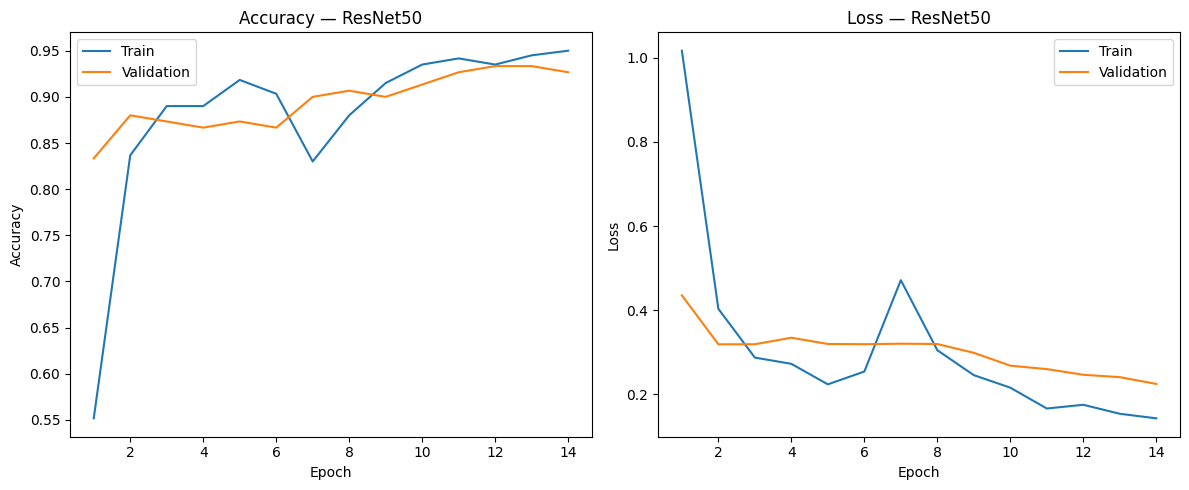


ĐANG TRAIN: DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.3788 - loss: 1.4912
Epoch 1: val_loss improved from None to 0.90586, saving model to /kaggle/working/banana_quality_results/models/banana_quality_DenseNet121_stage1.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_DenseNet121_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.4383 - loss: 1.2518 - val_accuracy: 0.6400 - val_loss: 0.9059 - learning_rate: 0.0010
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step - accuracy: 0.6207 - loss: 0.8757
Epoch 2: val_loss improved from 0.90586 to 0.65996, saving model to /kaggle/working/banana_quality_results/models/banana_quality_DenseNet121_stage1.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_DenseNet121_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 696ms/step - ac

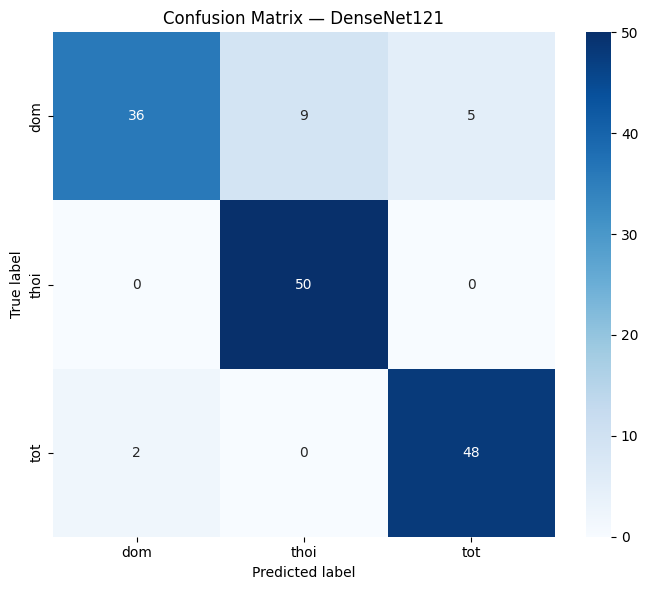

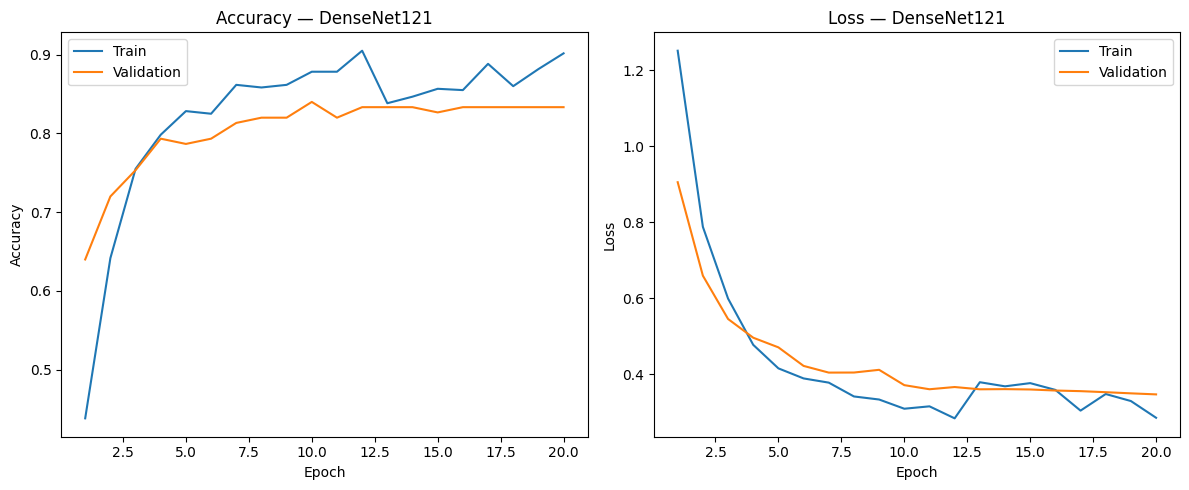


ĐANG TRAIN: InceptionV3
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.4940 - loss: 1.1241
Epoch 1: val_loss improved from None to 0.64482, saving model to /kaggle/working/banana_quality_results/models/banana_quality_InceptionV3_stage1.weights.h5

Epoch 1: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_InceptionV3_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 26s 888ms/step - accuracy: 0.6167 - loss: 0.8849 - val_accuracy: 0.7200 - val_loss: 0.6448 - learning_rate: 0.0010
Epoch 2/12
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.7963 - loss: 0.5074
Epoch 2: val_loss improved from 0.64482 to 0.50281, saving model to /kaggle/working/banana_quality_results/models/banana_quality_InceptionV3_stage1.weights.h5

Epoch 2: finished saving model to /kaggle/working/banana_quality_results/models/banana_quality_InceptionV3_stage1.weights.h5
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 685ms/step -

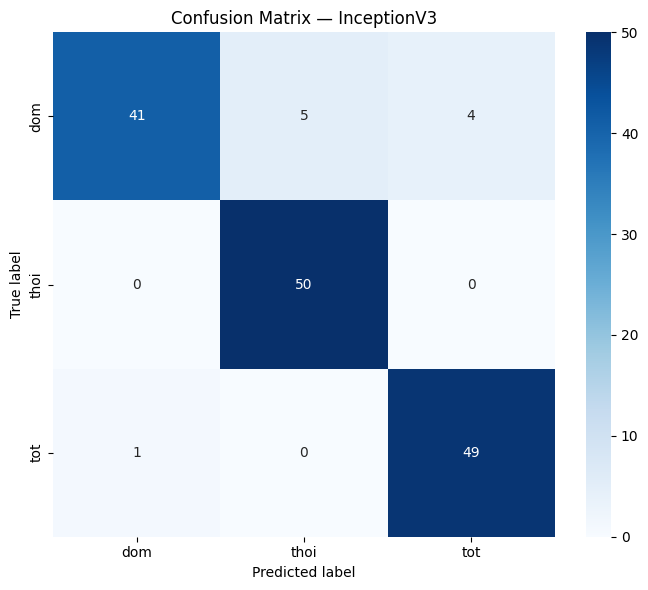

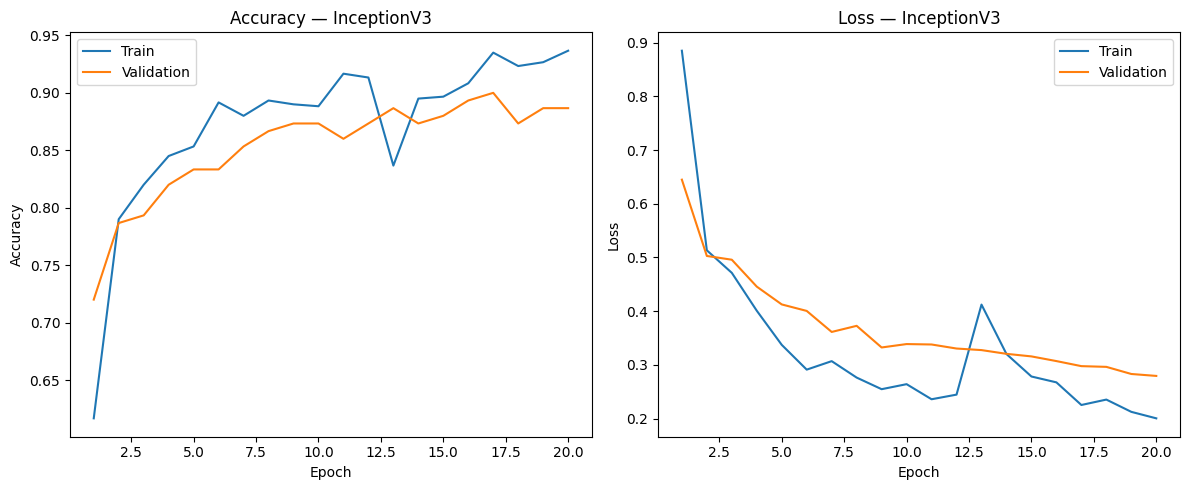

,Task,Model,Selected_Stage,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Test_Loss,Training_Time_Seconds
0,banana_quality,ResNet50,fine_tuned,0.933333,0.936311,0.933333,0.933486,0.140166,211.933702
1,banana_quality,InceptionV3,fine_tuned,0.933333,0.936603,0.933333,0.931714,0.220695,291.657563
2,banana_quality,EfficientNetB0,fine_tuned,0.893333,0.900162,0.893333,0.889217,0.260023,274.344789
3,banana_quality,DenseNet121,fine_tuned,0.893333,0.900162,0.893333,0.889217,0.245204,314.682145
4,banana_quality,MobileNetV3Small,fine_tuned,0.886667,0.893894,0.886667,0.881779,0.253362,242.266619


In [27]:
MODEL_NAMES = [
    "MobileNetV3Small",
    "EfficientNetB0",
    "ResNet50",
    "DenseNet121",
    "InceptionV3",
]

all_results = []

for model_name in MODEL_NAMES:
    try:
        result = train_and_evaluate(model_name)
        all_results.append(result)

        pd.DataFrame(all_results).to_csv(
            RESULT_DIR / "five_models_results.csv", index=False
        )
    except Exception as error:
        print(f"LỖI Ở {model_name}: {type(error).__name__}: {error}")

results_df = pd.DataFrame(all_results)

if results_df.empty:
    raise RuntimeError("Không có mô hình nào train thành công.")

results_df = results_df.sort_values("Macro_F1", ascending=False).reset_index(drop=True)
results_df.to_csv(RESULT_DIR / "five_models_results.csv", index=False)
results_df

## Cell 11 — Biểu đồ so sánh năm mô hình

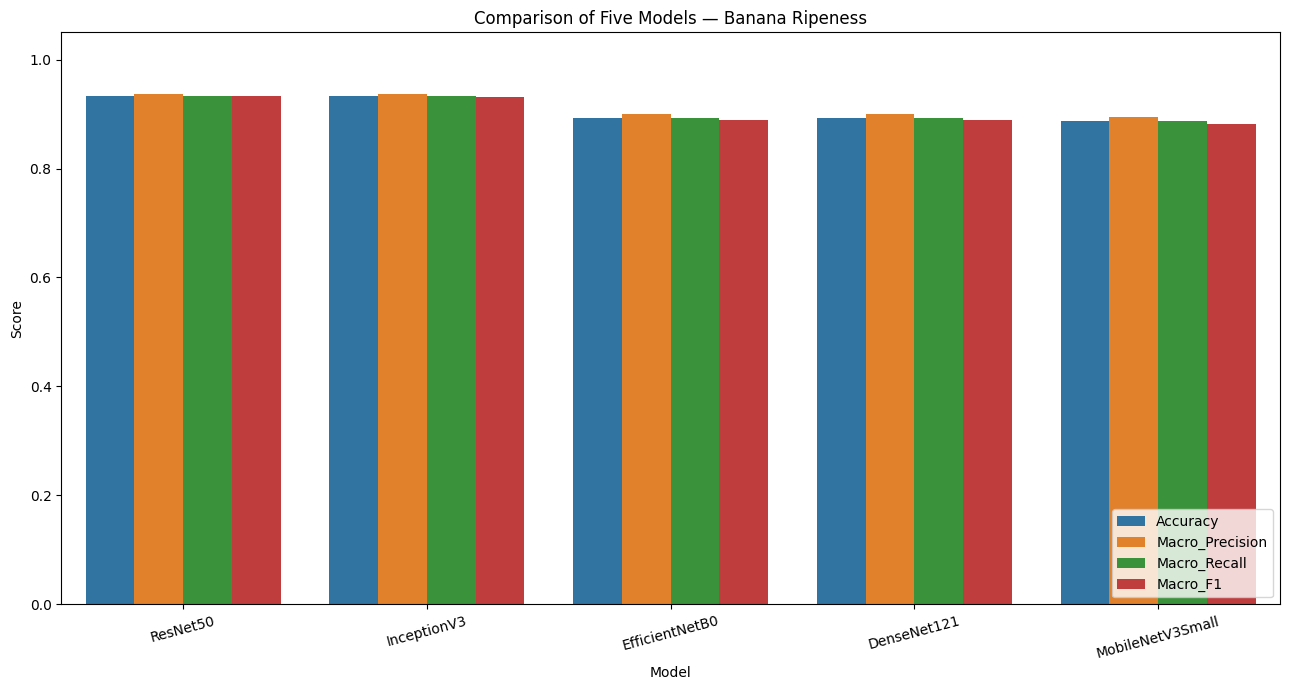

Mô hình tốt nhất: ResNet50
Accuracy: 0.9333
Macro F1: 0.9335


In [28]:
plot_data = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro_Precision", "Macro_Recall", "Macro_F1"],
    var_name="Metric",
    value_name="Score",
)

plt.figure(figsize=(13, 7))
sns.barplot(data=plot_data, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Comparison of Five Models — Banana Ripeness")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "five_models_comparison.png", dpi=300)
plt.show()

best_row = results_df.iloc[0]
print("Mô hình tốt nhất:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Macro F1:", round(best_row["Macro_F1"], 4))

## Cell 12 — Nén toàn bộ kết quả để tải về

In [29]:
archive_path = shutil.make_archive(
    "/kaggle/working/banana_results",
    "zip",
    root_dir=RESULT_DIR,
)

print("Đã tạo:", archive_path)
print("Mở mục Output của Kaggle để tải banana_results.zip về máy.")

Đã tạo: /kaggle/working/banana_results.zip
Mở mục Output của Kaggle để tải banana_results.zip về máy.


## Ghi chú quan trọng

- Dataset này chỉ dùng cho bài toán **Xanh – Chín – Quá chín**.
- Để train **Tốt – Đốm – Thối**, cần chuẩn bị dataset khác có ba thư mục `tot`, `dom`, `thoi`, rồi thay phần ánh xạ nhãn.
- Không chia lại train/validation/test cho từng mô hình; notebook đã cố định `SEED = 42` và chia đúng một lần.
- Khi so sánh mô hình, ưu tiên **Macro F1**, đồng thời xem Accuracy, confusion matrix và learning curves.
- Nếu hết GPU hoặc RAM, giảm `BATCH_SIZE` từ `16` xuống `8`.